In [28]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

df = pd.read_csv('/content/individual_reviews.csv')

df.head()

,appid,recommendationid,playtime_at_review_min,playtime_forever_min,voted_up,review_text,language,timestamp_created,timestamp_updated,written_during_early_access,steam_purchase,received_for_free,refunded,collected_at
0,1043240,239842462,335.0,335,True,I really wish this game has better bosses beca...,english,1794293639,1794293639,False,True,False,False,2026-11-17T01:15:28.118455+00:00
1,1043240,239737774,2520.0,2520,True,"It's on the harder side of the series, the bos...",english,1794169249,1794169249,False,True,False,False,2026-11-17T01:15:28.118465+00:00
2,1043240,239621144,378.0,425,True,"dear kagerou-san,\nsince the day i met you as ...",english,1794065751,1794065751,False,False,False,False,2026-11-17T01:15:28.118467+00:00
3,1043240,239070752,62.0,62,True,this game has my favorite gimmick in a touhou ...,english,1793508285,1793508297,False,True,False,False,2026-11-17T01:15:28.118469+00:00
4,1043240,237857494,6917.0,6917,True,Touhou 1.6,english,1792164553,1792164553,False,True,False,False,2026-11-17T01:15:28.118470+00:00


In [29]:
print("Dataset shape:", df.shape)

print("\nColumn names:")
print(df.columns.tolist())

Dataset shape: (6999, 14)

Column names:
['appid', 'recommendationid', 'playtime_at_review_min', 'playtime_forever_min', 'voted_up', 'review_text', 'language', 'timestamp_created', 'timestamp_updated', 'written_during_early_access', 'steam_purchase', 'received_for_free', 'refunded', 'collected_at']


In [30]:
print("DATA TYPES")
print(df.dtypes)

print("\nMISSING VALUES")
print(df.isnull().sum())

print("\nDUPLICATE REVIEW IDs")
print(df['recommendationid'].duplicated().sum())

print("\nDATASET INFORMATION")
df.info()

DATA TYPES
appid                            int64
recommendationid                 int64
playtime_at_review_min         float64
playtime_forever_min             int64
voted_up                          bool
review_text                     object
language                        object
timestamp_created                int64
timestamp_updated                int64
written_during_early_access       bool
steam_purchase                    bool
received_for_free                 bool
refunded                          bool
collected_at                    object
dtype: object

MISSING VALUES
appid                           0
recommendationid                0
playtime_at_review_min          1
playtime_forever_min            0
voted_up                        0
review_text                    23
language                        0
timestamp_created               0
timestamp_updated               0
written_during_early_access     0
steam_purchase                  0
received_for_free               0
refun

### Initial Data Inspection

The Steam reviews dataset contains 6,999 reviews and 14 columns.

The initial inspection found:

- No duplicate review IDs.
- One missing value in `playtime_at_review_min`.
- 23 missing values in `review_text`.
- Timestamp columns stored as numbers instead of readable dates.
- The recommendation column (`voted_up`) already stored as True or False.

**Cleaning decisions:**

The review with missing playtime was kept because the other information was still useful. Reviews with missing text were also kept because their recommendations could still be analysed.

No duplicate reviews needed to be removed because all review IDs were unique.

The original dataset was kept unchanged, and a separate copy was created for cleaning.

In [31]:
df_clean = df.copy()

df_clean = df_clean.drop_duplicates(
    subset='recommendationid',
    keep='first'
)

essential_columns = [
    'recommendationid',
    'appid',
    'voted_up',
    'timestamp_created'
]

df_clean = df_clean.dropna(
    subset=essential_columns
)

df_clean['playtime_at_review_hours'] = (
    df_clean['playtime_at_review_min'] / 60
)

df_clean['playtime_forever_hours'] = (
    df_clean['playtime_forever_min'] / 60
)

df_clean['timestamp_created'] = pd.to_datetime(
    df_clean['timestamp_created'],
    unit='s',
    utc=True
)

df_clean['timestamp_updated'] = pd.to_datetime(
    df_clean['timestamp_updated'],
    unit='s',
    utc=True
)

df_clean['recommendation'] = df_clean['voted_up'].astype(int)

df_clean.head()

,appid,recommendationid,playtime_at_review_min,playtime_forever_min,voted_up,review_text,language,timestamp_created,timestamp_updated,written_during_early_access,steam_purchase,received_for_free,refunded,collected_at,playtime_at_review_hours,playtime_forever_hours,recommendation
0,1043240,239842462,335.0,335,True,I really wish this game has better bosses beca...,english,2026-11-10 06:53:59+00:00,2026-11-10 06:53:59+00:00,False,True,False,False,2026-11-17T01:15:28.118455+00:00,5.583333,5.583333,1
1,1043240,239737774,2520.0,2520,True,"It's on the harder side of the series, the bos...",english,2026-11-08 20:20:49+00:00,2026-11-08 20:20:49+00:00,False,True,False,False,2026-11-17T01:15:28.118465+00:00,42.000000,42.000000,1
2,1043240,239621144,378.0,425,True,"dear kagerou-san,\nsince the day i met you as ...",english,2026-11-07 15:35:51+00:00,2026-11-07 15:35:51+00:00,False,False,False,False,2026-11-17T01:15:28.118467+00:00,6.300000,7.083333,1
3,1043240,239070752,62.0,62,True,this game has my favorite gimmick in a touhou ...,english,2026-11-01 04:44:45+00:00,2026-11-01 04:44:57+00:00,False,True,False,False,2026-11-17T01:15:28.118469+00:00,1.033333,1.033333,1
4,1043240,237857494,6917.0,6917,True,Touhou 1.6,english,2026-10-16 15:29:13+00:00,2026-10-16 15:29:13+00:00,False,True,False,False,2026-11-17T01:15:28.118470+00:00,115.283333,115.283333,1


### Data Cleaning Results

The cleaning process was completed using a separate copy of the original dataset.

The following changes were made:

1. Duplicate review IDs were checked, and none were found.
2. Missing values were checked, and no reviews needed to be removed.
3. Playtime was converted from minutes into hours.
4. Review timestamps were converted into readable dates.
5. Recommendations were converted into numbers (1 = Positive, 0 = Negative).

Three new columns were added to store playtime in hours and numerical recommendations.

The cleaned dataset is now ready for further analysis and visualisation.

In [32]:
print("Cleaned dataset shape:", df_clean.shape)

print("\nMissing values:")
print(df_clean.isnull().sum())

Cleaned dataset shape: (6999, 17)

Missing values:
appid                           0
recommendationid                0
playtime_at_review_min          1
playtime_forever_min            0
voted_up                        0
review_text                    23
language                        0
timestamp_created               0
timestamp_updated               0
written_during_early_access     0
steam_purchase                  0
received_for_free               0
refunded                        0
collected_at                    0
playtime_at_review_hours        1
playtime_forever_hours          0
recommendation                  0
dtype: int64


In [33]:
print("PLAYTIME AT REVIEW (HOURS)")
print(df_clean['playtime_at_review_hours'].describe())

print("\nTOTAL PLAYTIME (HOURS)")
print(df_clean['playtime_forever_hours'].describe())

PLAYTIME AT REVIEW (HOURS)
count     6998.000000
mean        93.137692
std        639.937894
min          0.083333
25%          3.350000
50%          9.458333
75%         36.316667
max      37059.650000
Name: playtime_at_review_hours, dtype: float64

TOTAL PLAYTIME (HOURS)
count     6999.000000
mean       108.959792
std        665.603800
min          0.083333
25%          4.700000
50%         14.266667
75%         51.441667
max      37264.233333
Name: playtime_forever_hours, dtype: float64


In [34]:
top_playtime = df_clean[
    ['appid', 'recommendationid',
     'playtime_at_review_hours',
     'playtime_forever_hours']
].sort_values(
    by='playtime_at_review_hours',
    ascending=False
)

top_playtime.head(10)

,appid,recommendationid,playtime_at_review_hours,playtime_forever_hours
4623,3910,238619550,37059.650000,37264.233333
4695,3910,231721002,15081.233333,15470.716667
5902,594570,234536452,10436.650000,10760.166667
4692,3910,231839240,9969.716667,9982.050000
4827,3910,221781270,9720.616667,11071.283333
4765,3910,226349346,8679.316667,9355.383333
4698,3910,231513156,8591.183333,9534.366667
4681,3910,232687958,7598.250000,7598.250000
4849,3910,218825872,7385.733333,7689.550000
4610,3910,239703536,7283.816667,7384.416667


In [35]:
bins = [0, 2, 10, 50, 100, float('inf')]

labels = [
    '0–2 hours',
    '2–10 hours',
    '10–50 hours',
    '50–100 hours',
    '100+ hours'
]

df_clean['playtime_group'] = pd.cut(
    df_clean['playtime_at_review_hours'],
    bins=bins,
    labels=labels,
    right=False
)

df_clean[['playtime_at_review_hours', 'playtime_group']].head(10)

,playtime_at_review_hours,playtime_group
0,5.583333,2–10 hours
1,42.000000,10–50 hours
2,6.300000,2–10 hours
3,1.033333,0–2 hours
4,115.283333,100+ hours
5,1.583333,0–2 hours
6,6.733333,2–10 hours
7,4.400000,2–10 hours
8,4.683333,2–10 hours
9,0.816667,0–2 hours


### Review Statistics by Playtime Group

Reviews were divided into five groups based on how long players had played before writing their reviews: 0–2, 2–10, 10–50, 50–100, and 100+ hours.

For each group, the number of reviews, positive and negative reviews, average playtime, median playtime, and positive recommendation percentage were calculated.

The results show that the 0–2 hour group had the lowest positive recommendation rate at 63.33%. This increased to 76.80% in the 2–10 hour group and reached around 85% in groups with 10 or more hours of playtime.

The 100+ hour group had the highest positive recommendation rate at 85.48%.

Overall, the results suggest that players with more playtime were more likely to recommend a game. However, this does not mean that longer playtime directly causes more positive recommendations.

### Positive Recommendation Percentage by Playtime Group

This bar chart shows the percentage of positive recommendations in each playtime group.

The 0–2 hour group has the lowest positive recommendation rate at 63.33%. This increases to 76.80% in the 2–10 hour group and around 85% in groups with 10 or more hours.

The 100+ hour group has the highest rate at 85.48%.

Overall, the chart shows that players with more playtime tend to recommend games more often.

In [36]:
summary = (
    df_clean.dropna(subset=['playtime_group'])
    .groupby('playtime_group', observed=False)
    .agg(
        review_count=('recommendation', 'count'),
        positive_reviews=('recommendation', 'sum'),
        avg_playtime_hours=('playtime_at_review_hours', 'mean'),
        median_playtime_hours=('playtime_at_review_hours', 'median'),
        recommendation_percentage=('recommendation', 'mean')
    )
)

summary['negative_reviews'] = (
    summary['review_count'] - summary['positive_reviews']
)

summary['recommendation_percentage'] *= 100

summary

,review_count,positive_reviews,avg_playtime_hours,median_playtime_hours,recommendation_percentage,negative_reviews
playtime_group,,,,,,
0–2 hours,1317,834,0.766287,0.650000,63.325740,483
2–10 hours,2267,1741,5.555036,5.400000,76.797530,526
10–50 hours,1959,1668,23.066326,19.866667,85.145482,291
50–100 hours,539,457,70.835220,69.116667,84.786642,82
100+ hours,916,783,605.685571,245.375000,85.480349,133


### Analysis of Recommendations by Playtime Group

The results show a relationship between playtime and positive recommendations.

The 0–2 hour group had the lowest positive recommendation rate at 63.33%. This increased to 76.80% in the 2–10 hour group and around 85% in groups with 10 or more hours of playtime.

The 100+ hour group had the highest rate at 85.48%. However, the differences between groups with 10 or more hours were small.

In the 100+ hour group, the average playtime was 605.69 hours, while the median was 245.38 hours. This suggests that some players with extremely high playtime increased the average.

Overall, the results suggest that longer playtime is associated with more positive recommendations, but this does not prove that longer playtime causes players to recommend a game.

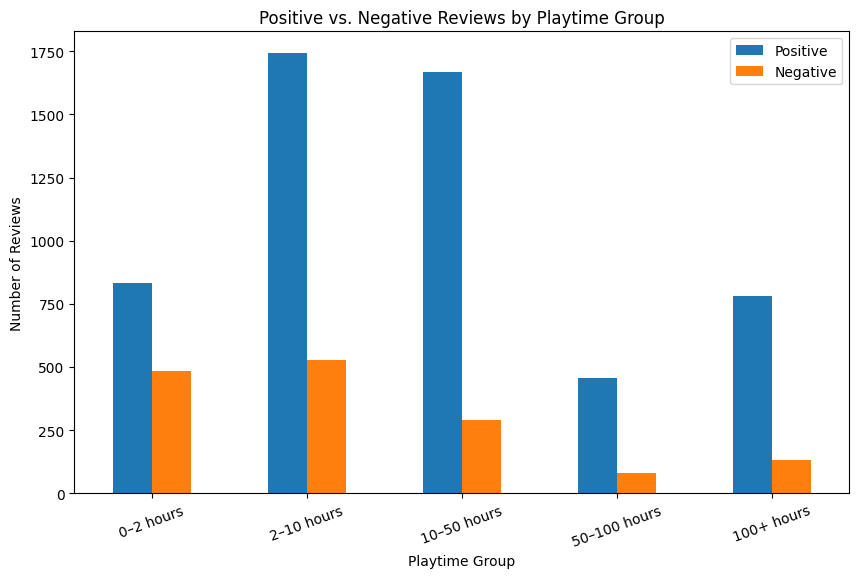

In [37]:
summary[
    ['positive_reviews', 'negative_reviews']
].plot(
    kind='bar',
    figsize=(10, 6)
)

plt.title('Positive vs. Negative Reviews by Playtime Group')
plt.xlabel('Playtime Group')
plt.ylabel('Number of Reviews')
plt.xticks(rotation=20)
plt.legend(['Positive', 'Negative'])
plt.show()

### Positive vs. Negative Reviews by Playtime Group

This bar chart compares the number of positive and negative reviews in each playtime group.

Positive reviews outnumber negative reviews in all five groups. The 2–10 hour group has the highest number of reviews, with 1,741 positive and 526 negative reviews.

The 0–2 hour group has the lowest percentage of positive recommendations. Groups with 10 or more hours of playtime have higher positive recommendation rates.

Overall, positive recommendations are more common than negative recommendations across all playtime groups.

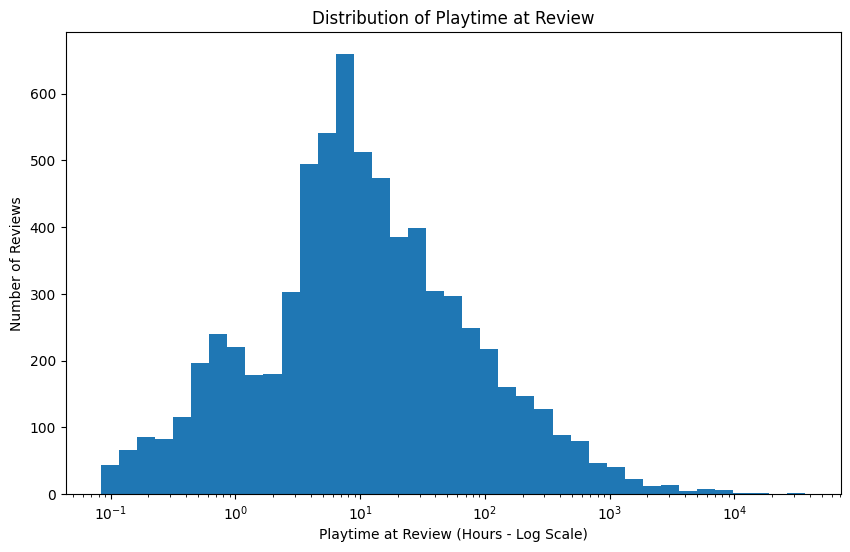

In [38]:
playtime_data = df_clean['playtime_at_review_hours'].dropna()

bins = np.logspace(
    np.log10(playtime_data.min()),
    np.log10(playtime_data.max()),
    40
)

plt.figure(figsize=(10, 6))

plt.hist(playtime_data, bins=bins)

plt.xscale('log')
plt.title('Distribution of Playtime at Review')
plt.xlabel('Playtime at Review (Hours - Log Scale)')
plt.ylabel('Number of Reviews')

plt.show()

### Distribution of Playtime at Review

This histogram shows how much time players had spent playing a game when they wrote their reviews. A logarithmic horizontal axis is used to make the wide range of playtime values easier to see, including extremely high values.

The median playtime is 9.46 hours, while the mean is 93.14 hours. This large difference shows that the data is strongly right-skewed. Most players had lower playtime, while a small number had very high playtime.

The graph shows how playtime varies between players and explains why both the mean and median are useful when describing the data.

### Statistical Analysis: Playtime Group and Recommendations

A Chi-square test of independence was used to check whether playtime group is associated with player recommendations.

The test compares the actual numbers of positive and negative reviews in each playtime group with the numbers expected if there were no relationship between playtime and recommendations.

A p-value below 0.05 indicates a statistically significant association between the two variables.

However, the test can only identify whether an association exists. It cannot prove that higher playtime causes players to recommend games.

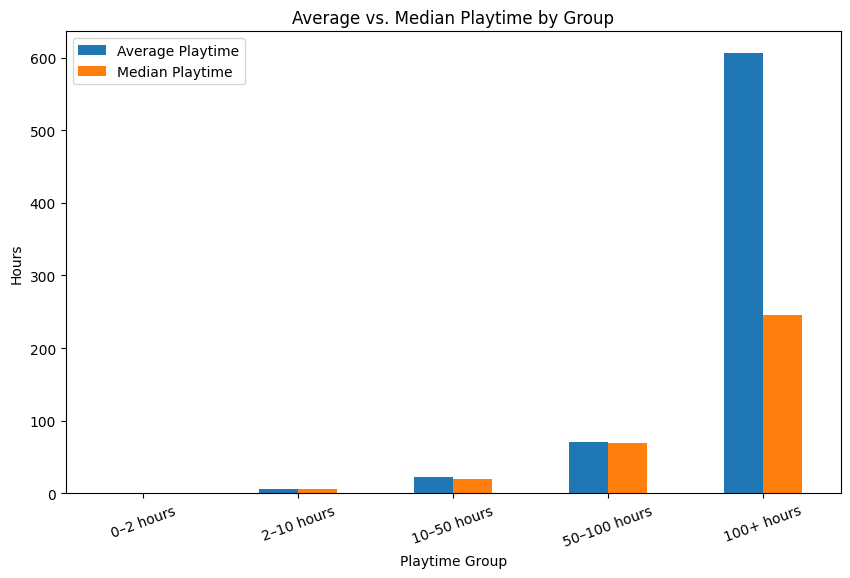

In [39]:
summary[
    ['avg_playtime_hours', 'median_playtime_hours']
].plot(
    kind='bar',
    figsize=(10, 6)
)

plt.title('Average vs. Median Playtime by Group')
plt.xlabel('Playtime Group')
plt.ylabel('Hours')
plt.xticks(rotation=20)
plt.legend(['Average Playtime', 'Median Playtime'])
plt.show()

In [40]:
q1 = df_clean['playtime_at_review_hours'].quantile(0.25)
q3 = df_clean['playtime_at_review_hours'].quantile(0.75)

iqr = q3 - q1
upper_bound = q3 + 1.5 * iqr

print("Q1:", q1)
print("Q3:", q3)
print("IQR:", iqr)
print("Potential high-playtime outlier threshold:", upper_bound)

print("Number above threshold:",
      (df_clean['playtime_at_review_hours'] > upper_bound).sum())

Q1: 3.35
Q3: 36.31666666666667
IQR: 32.96666666666667
Potential high-playtime outlier threshold: 85.76666666666668
Number above threshold: 1022


### Investigation of Unusually High Playtime

The interquartile range (IQR) method was used to identify unusually high playtime values. The upper threshold was approximately 85.77 hours, and 1,022 reviews were above this value.

The 10 highest playtime records were inspected. Some players had accumulated thousands of hours in their games. Although these values are unusually high, they may represent genuine long-term players.

Therefore, these records were kept instead of being automatically removed. This helps preserve useful information and avoids excluding genuine player experiences from the analysis.


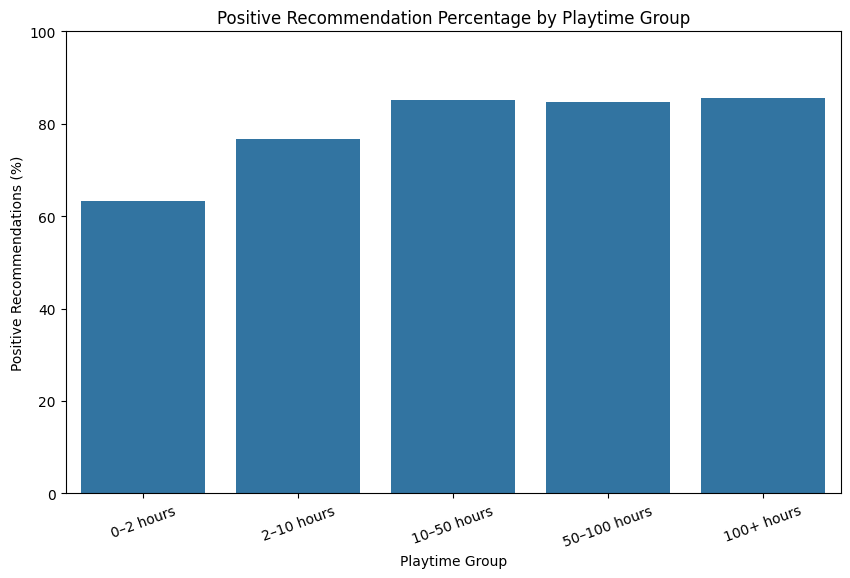

In [41]:
plt.figure(figsize=(10, 6))

sns.barplot(
    x=summary.index,
    y=summary['recommendation_percentage']
)

plt.title('Positive Recommendation Percentage by Playtime Group')
plt.xlabel('Playtime Group')
plt.ylabel('Positive Recommendations (%)')
plt.ylim(0, 100)
plt.xticks(rotation=20)

plt.show()

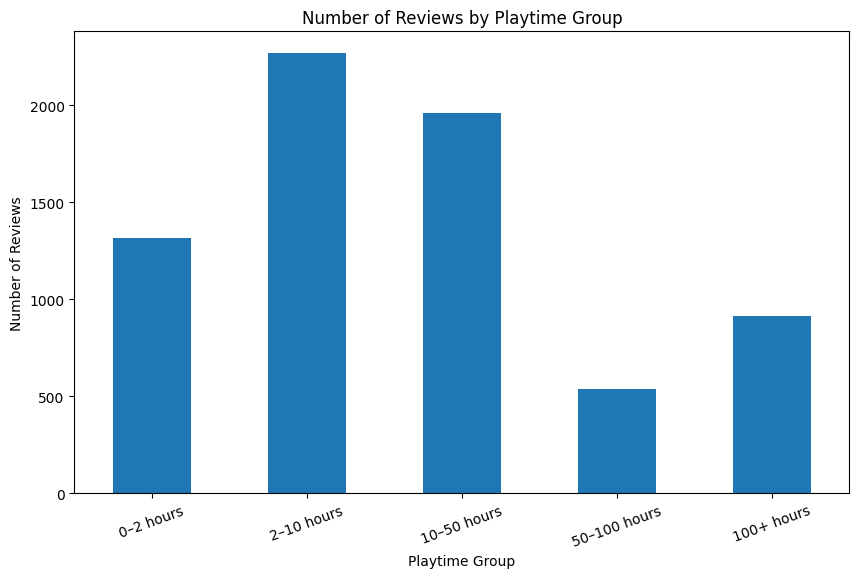

In [42]:
summary['review_count'].plot(
    kind='bar',
    figsize=(10, 6),
    title='Number of Reviews by Playtime Group'
)

plt.xlabel('Playtime Group')
plt.ylabel('Number of Reviews')
plt.xticks(rotation=20)
plt.show()

### Visual Analysis of Review Playtime

**Positive Recommendation Percentage by Playtime Group**

The graph shows that positive recommendation percentages generally increase with playtime. The lowest percentage is in the 0–2 hour group (63.33%), while the highest is in the 100+ hour group (85.48%). This suggests that players with more playtime are more likely to recommend a game.

**Number of Reviews by Playtime Group**

The graph shows that the 2–10 hour group contains the most reviews (2,267), followed by the 10–50 hour group (1,959). The 50–100 hour group contains the fewest reviews (539).

Together, these graphs show how reviews are distributed across playtime groups and how recommendation percentages differ between them.

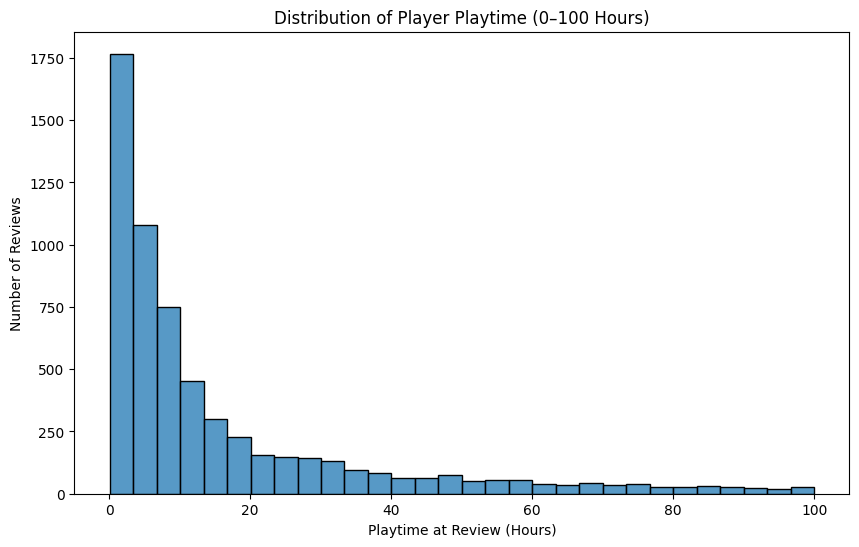

In [43]:
plt.figure(figsize=(10, 6))

sns.histplot(
    data=df_clean[df_clean['playtime_at_review_hours'] <= 100],
    x='playtime_at_review_hours',
    bins=30
)

plt.title('Distribution of Player Playtime (0–100 Hours)')
plt.xlabel('Playtime at Review (Hours)')
plt.ylabel('Number of Reviews')

plt.show()

### Distribution of Player Playtime

The histogram shows that player playtime is right-skewed. Most reviews were written by players with fewer hours in the game, and the number of reviews decreases as playtime increases.

A small number of players have extremely high playtime, creating a long tail on the right side of the graph. This explains why the mean playtime (93.14 hours) is much higher than the median (9.46 hours).

The second histogram focuses on players with up to 100 hours of playtime. This makes the distribution easier to see for players with lower and moderate playtime. The original dataset remains unchanged.

In [44]:
from scipy.stats import chi2_contingency

contingency_table = pd.crosstab(
    df_clean['playtime_group'],
    df_clean['recommendation']
)

contingency_table.columns = ['Negative', 'Positive']

print("Contingency Table:")
display(contingency_table)

chi2, p_value, dof, expected = chi2_contingency(
    contingency_table
)

print("Chi-square statistic:", chi2)
print("P-value:", p_value)
print("Degrees of freedom:", dof)

Contingency Table:


,Negative,Positive
playtime_group,,
0–2 hours,483,834
2–10 hours,526,1741
10–50 hours,291,1668
50–100 hours,82,457
100+ hours,133,783


Chi-square statistic: 272.437067060686
P-value: 9.516019613258403e-58
Degrees of freedom: 4


### Chi-Square Test of Independence

The Chi-square test produced a value of 272.44, with 4 degrees of freedom and a p-value of approximately 9.52 × 10⁻⁵⁸.

Since the p-value is much smaller than 0.05, the null hypothesis was rejected.

This indicates a statistically significant relationship between playtime group and player recommendations. Different playtime groups showed different patterns of positive and negative reviews.

However, this result does not prove that higher playtime causes players to recommend a game. It only shows that the two variables are associated.

In [45]:
n = contingency_table.to_numpy().sum()

cramers_v = np.sqrt(
    chi2 / (n * min(
        contingency_table.shape[0] - 1,
        contingency_table.shape[1] - 1
    ))
)

print("Cramér's V:", cramers_v)

Cramér's V: 0.19730865177932336


### Strength of the Relationship (Cramér's V)

Cramér's V was used to measure the strength of the relationship between playtime groups and player recommendations.

The result was 0.1973, indicating a relatively weak relationship.

This means that playtime is associated with player recommendations, but other factors may also influence whether players recommend a game.

Overall, players with more playtime tended to give more positive recommendations, but the relationship was relatively weak.

## Overall Conclusion

After cleaning and analysing 6,999 Steam reviews, several patterns were identified.

Players with less than 2 hours of playtime had the lowest positive recommendation rate at 63.33%. In comparison, players with 10 or more hours had positive recommendation rates of around 85%.

Most reviews came from players with relatively low playtime. A small number of players had extremely high playtime, which increased the average. These records were kept because they could represent genuine player activity.

The Chi-square test showed a statistically significant relationship between playtime groups and player recommendations. However, Cramér's V was 0.1973, indicating that the relationship was relatively weak.

Overall, players with more playtime tended to give more positive recommendations. However, playtime alone does not explain why players recommend a game, as other factors may also influence their decisions.

In [46]:
df_clean.to_csv('/content/individual_reviews_cleaned.csv', index=False)

print("Cleaned dataset saved successfully.")

Cleaned dataset saved successfully.


In [47]:
from google.colab import files
files.download('/content/individual_reviews_cleaned.csv')

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>